# 02 - Introducción a la clasificación 1

**Hecho por:** Joshua Sancho

**Correo:** [joshsan1408@gmail.com](mailto:joshsan1408@gmail.com)

**LinkedIn:** [joshsan1408](https://www.linkedin.com/in/joshsan1408/)

In [102]:
%matplotlib inline

from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier


In [103]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

## 1. Comprensión del problema

Una fila representa un cliente. Las **entradas** describen al cliente; el
**objetivo** es la respuesta que queremos predecir. Queremos predecir `Churn`: si abandonó (`Yes=1`)
o permaneció (`No=0`). Es **clasificación** porque buscamos una categoría.

### Diccionario de datos

El conjunto contiene 21 columnas: 19 entradas para el modelo, un identificador y
la variable objetivo. La tabla describe los valores originales; más adelante
convertiremos `Churn` a 0/1 y prepararemos las entradas numéricas y categóricas.

| Variable | Significado y valores | Función |
| --- | --- | --- |
| `customerID` | Identificador del cliente | Identificador; no se usa como entrada |
| `gender` | Género registrado: `Female` o `Male` | Entrada |
| `SeniorCitizen` | Indica si el cliente es adulto mayor: `1` = sí, `0` = no | Entrada |
| `Partner` | Indica si tiene pareja: `Yes` o `No` | Entrada |
| `Dependents` | Indica si tiene personas dependientes: `Yes` o `No` | Entrada |
| `tenure` | Meses de permanencia | Entrada |
| `PhoneService` | Servicio telefónico contratado: `Yes` o `No` | Entrada |
| `MultipleLines` | Varias líneas telefónicas: `Yes`, `No` o `No phone service` (sin servicio telefónico) | Entrada |
| `InternetService` | Servicio de Internet contratado: `DSL`, `Fiber optic` (fibra óptica) o `No` | Entrada |
| `OnlineSecurity` | Seguridad en línea: `Yes`, `No` o `No internet service` (sin servicio de Internet) | Entrada |
| `OnlineBackup` | Copia de seguridad en línea: `Yes`, `No` o `No internet service` | Entrada |
| `DeviceProtection` | Protección de dispositivos: `Yes`, `No` o `No internet service` | Entrada |
| `TechSupport` | Soporte técnico: `Yes`, `No` o `No internet service` | Entrada |
| `StreamingTV` | Televisión por streaming: `Yes`, `No` o `No internet service` | Entrada |
| `StreamingMovies` | Películas por streaming: `Yes`, `No` o `No internet service` | Entrada |
| `Contract` | Tipo de contrato: `Month-to-month` (mensual), `One year` (un año) o `Two year` (dos años) | Entrada |
| `PaperlessBilling` | Facturación electrónica: `Yes` o `No` | Entrada |
| `PaymentMethod` | Forma de pago: `Electronic check` (cheque electrónico), `Mailed check` (cheque por correo), `Bank transfer (automatic)` (transferencia automática) o `Credit card (automatic)` (tarjeta de crédito automática) | Entrada |
| `MonthlyCharges` | Cargo mensual | Entrada |
| `TotalCharges` | Cargos acumulados registrados; los espacios en blanco se tratarán como datos ausentes | Entrada |
| `Churn` | Indica si abandonó: `Yes` (se codificará como `1`) o `No` (se codificará como `0`) | Objetivo |

En las columnas con valores `Yes` y `No`, significan «sí» y «no».
Las categorías `No internet service` y `No phone service` indican ausencia del
servicio correspondiente; no son datos ausentes.

Una campaña podría usar las predicciones para identificar clientes a contactar.
Importa detectar abandonos, pero también evitar contactos innecesarios.
Predecir abandono no demuestra que contactar al cliente lo evite.

## 2. Comprensión de los datos

### Cargar y revisar

Usamos Telco Customer Churn, versión 1.
Conservamos `source_data` sin modificar y trabajamos con una copia.
`head()` muestra las primeras cinco filas para reconocer las columnas y cómo es un registro.

In [104]:
dataset_path = Path(kagglehub.dataset_download("blastchar/telco-customer-churn/versions/1"))
csv_path = next(dataset_path.glob("*.csv"))
source_data = pd.read_csv(csv_path)
data = source_data.copy()
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


`shape` devuelve `(filas, columnas)`. Comprobamos cuántos clientes y campos trae
la fuente antes de estudiar sus relaciones.

In [105]:
print(f"Filas: {data.shape[0]}\nColumnas: {data.shape[1]}")

Filas: 7043
Columnas: 21


`info()` muestra el tipo de cada columna y cuántos valores están presentes.
Buscamos tipos inesperados o datos incompletos.

In [106]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` aparece como texto, aunque representa un importe.
`nunique()` cuenta los valores distintos: una columna con dos valores es **binaria**.


In [107]:
data.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

`unique()` muestra los valores distintos de cada columna de texto. Revisamos
sus etiquetas antes de convertirlas en booleanos o categorías. Omitimos
`customerID` y `TotalCharges` para no imprimir miles de valores.

In [108]:
for column in data.select_dtypes(exclude="number").columns:
    if column not in ["customerID", "TotalCharges"]:
        print(f"{column}: {data[column].unique().tolist()}")

gender: ['Female', 'Male']
Partner: ['Yes', 'No']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No phone service', 'No', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'Yes', 'No internet service']
OnlineBackup: ['Yes', 'No', 'No internet service']
DeviceProtection: ['No', 'Yes', 'No internet service']
TechSupport: ['No', 'Yes', 'No internet service']
StreamingTV: ['No', 'Yes', 'No internet service']
StreamingMovies: ['No', 'Yes', 'No internet service']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['Yes', 'No']
PaymentMethod: ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn: ['No', 'Yes']


Convertimos `TotalCharges` a número. Con `errors="coerce"`, un valor que no se
puede convertir, como un espacio en blanco, pasa a ser ausente.

Las entradas de dos valores se convierten en **booleanos**: `True` (sí, equivale
a 1) y `False` (no, equivale a 0). Por ejemplo, `is_male` indica si el valor original
era `Male`; `has_partner`, si el cliente tiene pareja.

Las entradas con varias opciones quedan como `category`. «Sin servicio» es una
opción válida, no un dato ausente. El objetivo `Churn` queda como `Yes=1`, `No=0`.


In [109]:
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

data["is_male"] = data["gender"] == "Male"
data["is_senior"] = data["SeniorCitizen"] == 1
data["has_partner"] = data["Partner"] == "Yes"
data["has_dependents"] = data["Dependents"] == "Yes"
data["has_phone_service"] = data["PhoneService"] == "Yes"
data["has_paperless_billing"] = data["PaperlessBilling"] == "Yes"
data = data.drop(columns=[
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling",
])

for column in [
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaymentMethod",
]:
    data[column] = data[column].astype("category")

data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

Comprobamos los tipos resultantes y los faltantes por columna.

In [110]:
pd.DataFrame({"DType": data.dtypes, "Null": data.isna().sum()})

,DType,Null
customerID,str,0
tenure,int64,0
MultipleLines,category,0
InternetService,category,0
OnlineSecurity,category,0
OnlineBackup,category,0
DeviceProtection,category,0
TechSupport,category,0
StreamingTV,category,0
StreamingMovies,category,0


Hay 11 datos ausentes en `TotalCharges`. Más adelante los completaremos con una
estimación calculada en entrenamiento: un ausente no equivale a cero.
Antes de dividir, comprobamos si hay filas o identificadores repetidos.


In [111]:
print(f"Duplicados exactos: {data.duplicated().sum()}")
print(f"Clientes repetidos: {data.customerID.duplicated().sum()}")

Duplicados exactos: 0
Clientes repetidos: 0


### Separar entradas y objetivo

- **`X`:** las 19 características que recibe el modelo, como antigüedad y contrato.
- **`y`:** la respuesta que queremos predecir, `Churn`.

Apartamos `customerID`: identifica al cliente, pero no describe su comportamiento.
Después agrupamos las entradas según su tipo: numéricas, categóricas y booleanas.


In [112]:
target_col = "Churn"
customer_ids = data["customerID"]
X = data.drop(columns=["customerID", target_col])
y = data[target_col]

In [113]:
numeric_features = X.select_dtypes("number").columns.tolist()
categorical_features = X.select_dtypes("category").columns.tolist()
boolean_features = X.select_dtypes("bool").columns.tolist()

### Separar entrenamiento y prueba

Reservamos **70 % para entrenamiento** y **30 % para prueba**:

- **Entrenamiento:** datos con los que aprende el modelo.
- **Validación:** partes del entrenamiento que usaremos para comparar opciones.
- **Prueba:** datos reservados para evaluar al final, después de elegir el modelo.

`stratify=y` conserva proporciones parecidas de abandono en ambas partes.
`random_state=42` permite repetir el mismo reparto. Conservamos los índices para
mantener cada cliente junto a su respuesta.

Desde aquí exploramos **solo entrenamiento**. Esta exploración se conoce como EDA.


In [114]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42,
)
train = X_train.join(y_train)
print(f"Entrenamiento: {len(X_train)}; prueba reservada: {len(X_test)}")

Entrenamiento: 4930; prueba reservada: 2113


### ¿Cuántos clientes permanecen y cuántos abandonan?

Comparamos cantidad y porcentaje de cada clase en entrenamiento.

In [115]:
class_balance = y_train.value_counts().sort_index().to_frame("Clientes")
class_balance["Porcentaje"] = class_balance["Clientes"] / len(y_train) * 100
class_balance.round(2)

,Clientes,Porcentaje
Churn,,
0,3622,73.47
1,1308,26.53


Permanecen 3.622 clientes y abandonan 1.308: aproximadamente 73,5 % y 26,5 %.
Las clases están desbalanceadas: tenemos más ejemplos de permanencia.

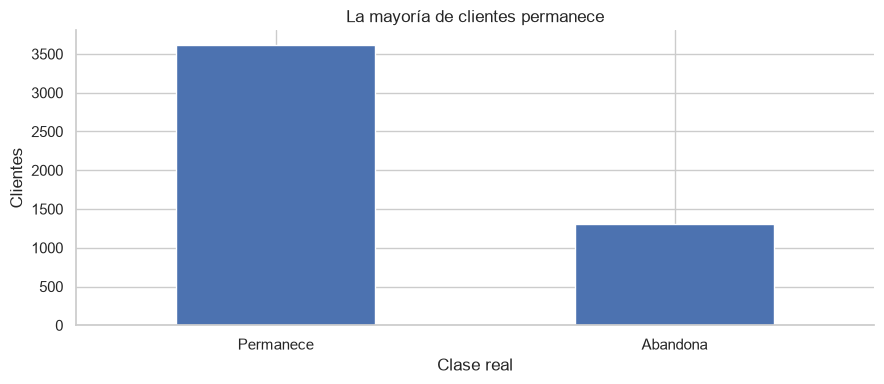

In [116]:
ax = class_balance["Clientes"].rename(index={0: "Permanece", 1: "Abandona"}).plot.bar(rot=0)
ax.set(xlabel="Clase real", ylabel="Clientes", title="La mayoría de clientes permanece")
plt.tight_layout()
plt.show()

### Desbalance de clases: ¿hay que corregirlo?

Hay más clientes que permanecen que clientes que abandonan. Esto puede ser
natural: **no necesitamos forzar una distribución 50/50**.

El problema aparece si el modelo aprende a predecir casi siempre permanencia.
Si 99 de cada 100 clientes permanecieran, esa regla tendría 99 % de aciertos,
pero no detectaría ningún abandono. Por eso revisaremos también los abandonos detectados.

#### Opciones para entrenar

| Opción | Qué hace | Qué debemos cuidar |
| --- | --- | --- |
| Conservar los datos | Entrena con la distribución original. | Es un punto de partida válido. |
| Undersampling | Quita al azar ejemplos de la clase mayoritaria. | Puede perder información útil. |
| Oversampling | Repite ejemplos de la clase minoritaria. | No añade información nueva y puede favorecer la memorización. |
| SMOTE | Crea ejemplos artificiales combinando valores de vecinos. | Pueden ser poco representativos. |
| Pesos de clase | Da más importancia a los errores de una clase al entrenar. | Puede detectar más abandonos y también generar más falsas alarmas. |

SMOTE convencional trabaja con números. Para datos con números y categorías
existe **SMOTENC**: mezclar códigos de categorías como si fueran cantidades
puede producir valores sin sentido.

Aquí compararemos **sin pesos** y **con pesos balanceados**; no cambiaremos las filas.
La validación dirá si ayudan. Si probáramos remuestreo, se aplicaría solo a los
datos con los que aprende el modelo en cada ronda; validación y prueba conservarían
su distribución original.


### ¿Cómo se distribuyen antigüedad y cargos?

`describe()` resume las entradas numéricas:

- `count`: datos presentes; `mean`: promedio; `std`: cuánto varían los valores.
- `min` y `max`: extremos; `50%`: mediana, el valor central al ordenar los datos.
- `25%` y `75%`: valores por debajo de los que está el 25 % y el 75 % de los datos.

`.T` coloca una variable por fila y `.round(2)` muestra dos decimales.


In [117]:
train[numeric_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tenure,4930.0,32.47,24.65,0.00,9.0,29.00,56.00,72.00
MonthlyCharges,4930.0,64.95,30.24,18.40,35.5,70.57,90.05,118.75
TotalCharges,4923.0,2305.07,2292.55,18.85,399.8,1389.20,3860.30,8684.80


La antigüedad tiene mediana de 29 meses. En `TotalCharges`, la media (2.305,07)
supera bastante a la mediana (1.389,20): los importes altos elevan el promedio.

Un **histograma** cuenta clientes por intervalos; `bins` indica cuántos intervalos usar.


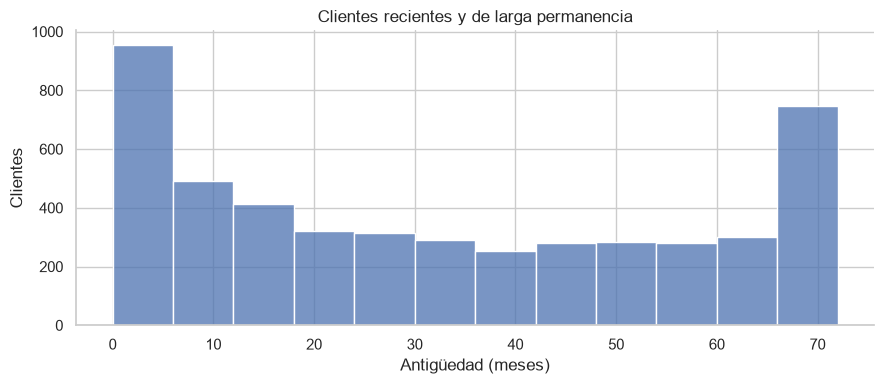

In [118]:
fig, ax = plt.subplots()
sns.histplot(data=train, x="tenure", bins=12, ax=ax)
ax.set(xlabel="Antigüedad (meses)", ylabel="Clientes", title="Clientes recientes y de larga permanencia")
plt.tight_layout()
plt.show()

Hay clientes en todo el rango, con concentraciones en los extremos.
Veamos si los cargos mensuales se concentran también en ciertas zonas.

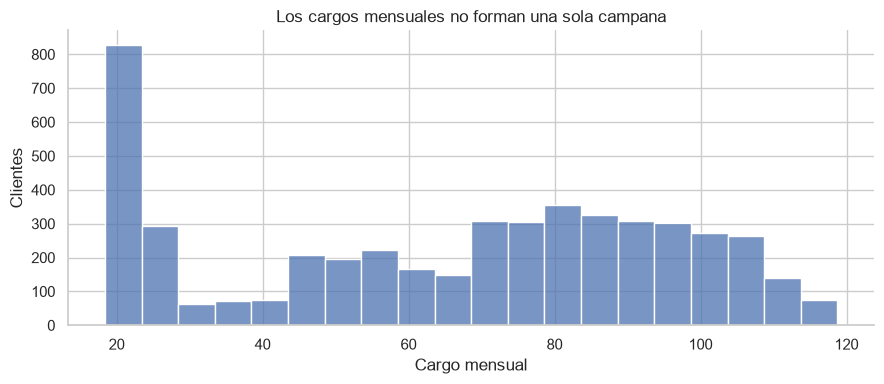

In [119]:
fig, ax = plt.subplots()
sns.histplot(data=train, x="MonthlyCharges", bins=20, ax=ax)
ax.set(xlabel="Cargo mensual", ylabel="Clientes", title="Los cargos mensuales no forman una sola campana")
plt.tight_layout()
plt.show()

Los cargos van de 18,40 a 118,75 y hay una concentración cerca del extremo bajo.
Un valor alto no es automáticamente un error: conservamos los extremos.
Ahora pasamos de describir entradas a relacionarlas con el abandono.

### ¿Cambia el abandono según el contrato?

`groupby()` reúne clientes con el mismo contrato y `agg()` calcula un resumen.
`size` cuenta clientes y `mean` promedia `Churn`. Como sus valores son 0 y 1,
ese promedio es la **tasa de abandono**: 0,40 significa que abandona el 40 %.
`observed=True` muestra solo categorías presentes en los datos.


In [120]:
contract_summary = train.groupby("Contract", observed=True)[target_col].agg(Clientes="size", Tasa="mean")
contract_summary.round(3)

,Clientes,Tasa
Contract,,
Month-to-month,2704,0.429
One year,1034,0.109
Two year,1192,0.030


La tasa es 42,9 % en contrato mensual, 10,9 % en un año y 3,0 % en dos años.
Los grupos tienen tamaños distintos; comparamos proporciones, no solo abandonos.

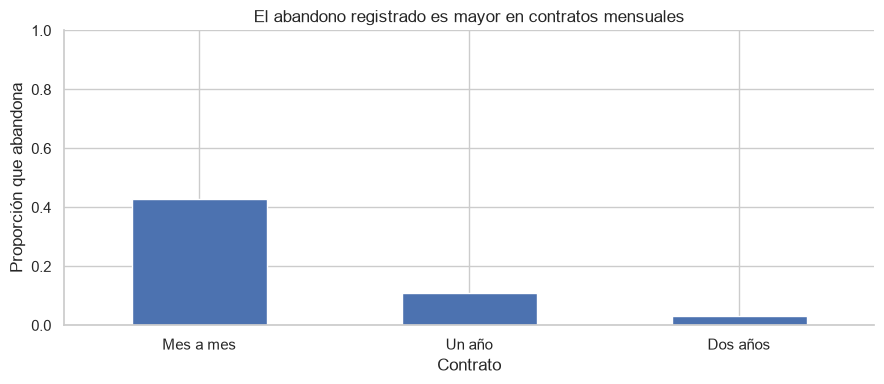

In [121]:
ax = contract_summary["Tasa"].rename(index={
    "Month-to-month": "Mes a mes", "One year": "Un año", "Two year": "Dos años",
}).plot.bar(rot=0)
ax.set(xlabel="Contrato", ylabel="Proporción que abandona", ylim=(0, 1),
       title="El abandono registrado es mayor en contratos mensuales")
plt.tight_layout()
plt.show()

Esta diferencia es una asociación: no demuestra que cambiar el contrato cause
permanencia. Revisemos otra característica que podría distinguir estos grupos.

### ¿Qué ocurre con la antigüedad?

`cut()` agrupa meses en intervalos. `assign()` añade esa agrupación a una copia
para explorar; el modelo seguirá recibiendo la antigüedad original.


In [122]:
tenure_groups = train.assign(tenure_range=pd.cut(
    train["tenure"], bins=[-1, 12, 24, 48, 72],
    labels=["0–12", "13–24", "25–48", "49–72"],
))
tenure_groups.groupby("tenure_range", observed=True)[target_col].agg(
    Clientes="size", Tasa="mean",
).round(3)

,Clientes,Tasa
tenure_range,,
0–12,1537,0.477
13–24,707,0.273
25–48,1118,0.199
49–72,1568,0.101


La tasa baja de 47,7 % en 0–12 meses a 10,1 % en 49–72 meses.
¿La diferencia por contrato se mantiene al comparar clientes de antigüedad similar?
`pivot_table()` organiza las tasas por rango y contrato.

In [123]:
tenure_groups.pivot_table(
    index="tenure_range", columns="Contract", values=target_col,
    aggfunc="mean", observed=True,
).round(3)

Contract,Month-to-month,One year,Two year
tenure_range,,,
0–12,0.514,0.099,0.000
13–24,0.370,0.069,0.000
25–48,0.329,0.104,0.015
49–72,0.280,0.129,0.038


El contrato mensual presenta la mayor tasa en cada rango, pero dentro de él baja
de 51,4 % a 28,0 % al aumentar la antigüedad. Contrato y antigüedad aportan contexto
juntos. `crosstab()` muestra cuántos clientes sostienen cada comparación.

In [124]:
pd.crosstab(tenure_groups["tenure_range"], tenure_groups["Contract"])

Contract,Month-to-month,One year,Two year
tenure_range,,,
0–12,1410,81,46
13–24,494,145,68
25–48,554,365,199
49–72,246,443,879


En 0–12 meses hay 1.410 contratos mensuales y solo 46 de dos años.
El 0 % de abandono de ese último grupo no garantiza riesgo nulo en futuros clientes.

### ¿Hay diferencias según el servicio de Internet?

Repetimos la agrupación con `InternetService`, mostrando tamaño y tasa juntos.

In [125]:
train.groupby("InternetService", observed=True)[target_col].agg(Clientes="size", Tasa="mean").round(3)

,Clientes,Tasa
InternetService,,
DSL,1685,0.192
Fiber optic,2177,0.418
No,1068,0.069


La tasa es 41,8 % en fibra, 19,2 % en DSL y 6,9 % sin Internet.
Estas diferencias pueden reflejar también contratos, antigüedad y otras características.

### ¿Qué cambia con la forma de pago?

Una categoría con muchos clientes puede acumular más abandonos por su tamaño.
Volvemos a comparar la proporción dentro de cada forma de pago.

In [126]:
train.groupby("PaymentMethod", observed=True)[target_col].agg(Clientes="size", Tasa="mean").round(3)

,Clientes,Tasa
PaymentMethod,,
Bank transfer (automatic),1086,0.163
Credit card (automatic),1067,0.147
Electronic check,1654,0.456
Mailed check,1123,0.195


El cheque electrónico tiene una tasa de 45,6 %, frente a 14,7 % en tarjeta automática.
No concluimos que el medio de pago cause abandono: observamos grupos distintos.

### ¿Los cargos son distintos entre clases?

Comparamos media y mediana de cargos mensuales y acumulados. `count` permite ver
cuántos importes están presentes en cada grupo.

In [127]:
train.groupby(target_col)[["MonthlyCharges", "TotalCharges"]].agg(["count", "mean", "median"]).round(2)

MonthlyCharges               TotalCharges                  
               count   mean median        count     mean   median
Churn                                                            
0               3622  61.32  64.45         3615  2568.79  1679.40
1               1308  75.00  80.00         1308  1576.22   705.08

En quienes abandonan, el cargo mensual mediano es mayor: 80,00 frente a 64,45.
Sin embargo, el total mediano es menor: 705,08 frente a 1.679,40.

En el **boxplot**, la línea central es la mediana y la caja contiene el 50 %
central de los datos. Los puntos fuera de los bigotes son posibles extremos,
no necesariamente errores.


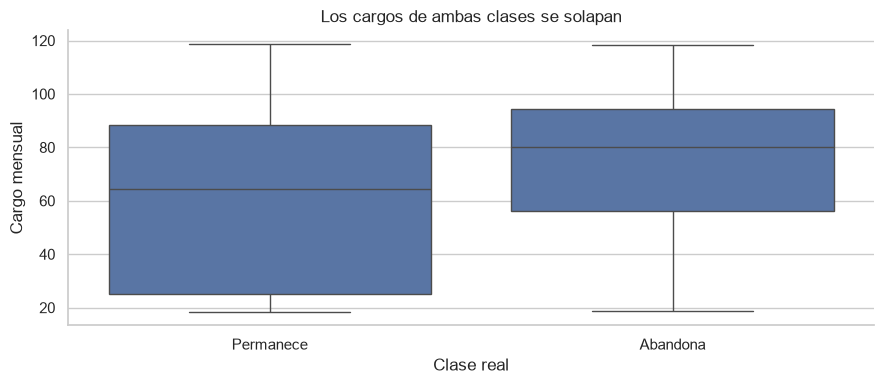

In [128]:
fig, ax = plt.subplots()
sns.boxplot(data=train, x=target_col, y="MonthlyCharges", ax=ax)
ax.set(xticks=[0, 1], xticklabels=["Permanece", "Abandona"],
       xlabel="Clase real", ylabel="Cargo mensual", title="Los cargos de ambas clases se solapan")
plt.tight_layout()
plt.show()

Aunque las medianas difieren, muchos cargos aparecen en ambas clases: una entrada
no separa perfectamente a los clientes. Los totales también dependen del tiempo
acumulado; revisamos su mediana por antigüedad antes de interpretar esa diferencia.

In [129]:
tenure_groups.groupby("tenure_range", observed=True)["TotalCharges"].agg(Clientes_con_dato="count", Mediana="median").round(2)

,Clientes_con_dato,Mediana
tenure_range,,
0–12,1530,176.25
13–24,707,1117.55
25–48,1118,2404.60
49–72,1568,5039.32


La mediana acumulada pasa de 176,25 a 5.039,32 entre el primer y último rango.
En entrenamiento faltan siete totales; por eso `count` no coincide siempre con el tamaño del grupo.

### ¿Qué nos llevamos al modelado?

- El abandono es minoritario: acertar muchas permanencias no basta.
- Contrato y antigüedad muestran diferencias de abandono, también al cruzarlos.
- Servicio y pago distinguen grupos, sin demostrar causas.
- Los cargos de ambas clases se solapan y los totales reflejan también antigüedad.

Conservamos las 19 entradas preparadas antes de dividir. Los rangos se
usaron para explorar, no como nuevas variables del modelo.

## 3. Preparación de los datos

Los modelos necesitan entradas numéricas. `ColumnTransformer` permite preparar
cada grupo de columnas de forma distinta.

### Categorías: convertir etiquetas en números

| Codificador | Ejemplo | Cuándo usarlo |
| --- | --- | --- |
| OneHotEncoder | Crea una columna 0/1 por contrato: mensual, un año y dos años. | Categorías sin orden natural. |
| OrdinalEncoder | Asigna códigos según un orden definido, como bajo=0, medio=1, alto=2. | Categorías ordenadas. |

Usamos **OneHotEncoder**: numerar DSL, fibra y sin Internet como 0, 1 y 2
introduciría un orden artificial.

- `drop=None`: conserva todas las columnas creadas. En KNN, evita favorecer una categoría por omitir su indicador.
- `handle_unknown="ignore"`: si aparece una categoría nueva, sus indicadores quedan en 0.


### Numéricos: completar ausentes y ajustar las escalas

#### ¿Qué hacemos con un dato ausente?

**Imputar** es reemplazarlo por una estimación. Primero revisamos cuántos faltan
y en qué clientes: no recuperamos el valor original.

| Opción | Cuándo considerarla y qué se pierde |
| --- | --- |
| Eliminar filas (`dropna`) | Si son pocas y perderlas no deja fuera a un grupo importante. Se pierden también sus datos conocidos. |
| Eliminar una columna | Si aporta poca información disponible. Se pierde esa entrada para todos los clientes. |
| Usar la media (`strategy="mean"`) | Punto de partida si los valores son aproximadamente simétricos, como una campana, y sin extremos que arrastren el promedio. |
| Usar la mediana (`strategy="median"`) | Útil ante asimetría (*skew*), por ejemplo muchos importes pequeños y unos pocos muy altos. Resiste mejor los extremos. |
| Estimar con otras variables | `KNNImputer` usa clientes parecidos; `IterativeImputer` aprende modelos para completar valores. Añaden configuración y cálculo, sin garantizar mejoras. |

Media y mediana son puntos de partida: la media no exige una distribución normal.
Repetir un mismo valor reduce la variación de los datos. La elección se puede
comparar en validación.

Para categorías podemos usar la **moda** (valor más frecuente) o una etiqueta
«ausente». Aquí las categorías no tienen faltantes.

#### Nuestra elección

En entrenamiento faltan siete `TotalCharges`. Elegimos la mediana porque los
importes altos desplazan la media: **2.305,07 de media frente a 1.389,20 de mediana**.
Así conservamos los clientes. No hemos comparado otras estrategias de imputación.

#### Escalar después de imputar

**Escalar** pone las variables en escalas comparables. `StandardScaler` resta
la media y divide por la desviación estándar, una medida de cuánto varían los valores.
Lo usamos en logística y KNN: en KNN, los cargos acumulados podrían dominar las
distancias solo porque sus números son mayores.

Primero completamos ausentes con `SimpleImputer`; después escalamos.
Las medianas y escalas se calculan solo con los datos usados para aprender.


### Booleanos: dejarlos pasar

`passthrough` conserva los booleanos como indicadores 0/1. No necesitan otra
codificación ni escalado.


In [130]:
scaled_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("boolean", "passthrough", boolean_features),
    ("categorical", OneHotEncoder(drop=None, handle_unknown="ignore",
                                  sparse_output=False), categorical_features),
])

### Preparación para árbol y bosque

Los árboles hacen preguntas como «¿antigüedad menor a 12 meses?». No calculan
distancias entre clientes, por lo que aquí no necesitan escalado. Conservamos
la imputación y la codificación de categorías.


In [131]:
unscaled_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("boolean", "passthrough", boolean_features),
    ("categorical", OneHotEncoder(drop=None, handle_unknown="ignore",
                                  sparse_output=False), categorical_features),
])

Un **pipeline** encadena preparación y modelo:

- `fit`: aprende cómo completar, escalar, codificar y clasificar.
- `predict`: aplica lo aprendido para predecir nuevas filas.

Aprender transformaciones con datos de validación o prueba daría pistas sobre
la evaluación: eso es **fuga de información** (*data leakage*). El pipeline ayuda
a evitarla, porque en cada ajuste aprende todos los pasos solo con entrenamiento.


In [132]:
pipeline = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("model", LogisticRegression(max_iter=1000)),
])

## 4. Modelado

### Regresión logística: combinar entradas para estimar abandono

Aprende un peso por entrada y un valor inicial, llamado **intercepto**. Combina
esos valores y usa una función en forma de S, la **sigmoide**, para obtener una
probabilidad entre 0 y 1. Aunque se llama regresión, aquí clasifica.

`predict_proba()` devuelve probabilidades y `predict()`, la clase. Con el corte
habitual de 0,50, una probabilidad de abandono de 0,70 produce clase 1.
`max_iter=1000` limita las repeticiones del cálculo que ajusta el modelo.

<img src="https://upload.wikimedia.org/wikipedia/commons/8/88/Logistic-curve.svg" alt="Curva logística en forma de S." width="600" style="background-color: white;">

Curva sigmoide. Fuente: [Qef — Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Logistic-curve.svg), dominio público.


In [133]:
logistic_model = LogisticRegression(max_iter=1000)

### KNN: mirar clientes parecidos

KNN busca los **K vecinos más cercanos** y toma su clase mayoritaria: si tres de
cinco abandonaron, predice abandono. Por eso escalamos antes de medir distancias.

Con pocos vecinos, cada cliente influye mucho; con más, la decisión se suaviza.
Probaremos `n_neighbors=5` y `15`.

<img src="https://upload.wikimedia.org/wikipedia/commons/e/e7/KnnClassification.svg" alt="Ejemplo de clasificación por vecinos cercanos." width="360" style="background-color: white;">

El punto verde es el caso nuevo; los círculos muestran conjuntos de vecinos. Fuente: [AnAj — Wikimedia Commons](https://commons.wikimedia.org/wiki/File:KnnClassification.svg), [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/).


In [134]:
knn_model = KNeighborsClassifier(n_jobs=1)

### Árbol: una secuencia de preguntas

Aprende preguntas como «¿antigüedad menor a un año?» y «¿contrato mensual?».
Cada respuesta conduce a otra pregunta hasta una **hoja**, donde decide la clase.

`max_depth` limita los niveles de preguntas. Un árbol muy profundo puede
**sobreajustar**: memorizar entrenamiento y fallar con clientes nuevos.
Probaremos profundidades 3 y 6.

<img src="https://www.w3.org/Data/demos/chunks/decision-tree/tree.png" alt="Árbol de decisiones sobre jugar golf según el clima." width="600" style="background-color: white;">

Ejemplo de preguntas y decisiones: jugar golf según el clima. Fuente: [Dave Raggett — W3C](https://www.w3.org/Data/demos/chunks/decision-tree/).


In [135]:
tree_model = DecisionTreeClassifier(random_state=42)

### Bosque: combinar muchos árboles

Entrena árboles con distintas muestras de clientes y opciones de entradas.
Después promedia sus probabilidades para decidir la clase. Así depende menos
de lo que haya aprendido un solo árbol.

`n_estimators=100` crea 100 árboles. Probaremos profundidad 6 y sin límite (`None`).

<img src="https://upload.wikimedia.org/wikipedia/commons/4/4e/Random_forest_explain.png" alt="Varios árboles combinan sus resultados en un bosque aleatorio." width="720" style="background-color: white;">

Varios árboles combinan sus resultados. Fuente: [TseKiChun — Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Random_forest_explain.png), [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/).


In [136]:
forest_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1)

### Baseline: una referencia sencilla

Un **baseline** permite preguntar si el modelo mejora una regla simple.
`DummyClassifier(strategy="most_frequent")` aprende la clase más frecuente
en entrenamiento y la repite para todos: aquí siempre predice permanencia.


In [137]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train);

### ¿Cómo elegimos entre modelos?

- **Recall:** de quienes abandonaron, ¿a cuántos detectamos?
- **Precisión:** de los clientes que señalamos, ¿cuántos abandonaron?

Si señalamos 10 clientes y 6 abandonaron, la precisión es 6/10 = **60 %**.
Si había 8 abandonos en total, el recall es 6/8 = **75 %**.

Elegimos por **recall de validación** para detectar abandonos. También revisamos
precisión: detectar más puede traer más contactos innecesarios.

#### ¿Qué significan las otras métricas de la búsqueda?

| Métrica | Qué resume |
| --- | --- |
| Balanced accuracy | Promedia el recall de permanencia y abandono, dando igual importancia a ambas clases. |
| F1 | Combina precisión y recall; baja cuando uno de los dos es bajo. |
| F1 weighted | Calcula F1 por clase y lo promedia dando más peso a la clase con más clientes. |

**`weighted` no corrige automáticamente el desbalance.** Por ejemplo,
`recall_weighted` equivale a accuracy (porcentaje total de aciertos): siempre
predecir permanencia lograría cerca de 73,5 %, aunque no detectara abandonos.

Los **pesos de clase** cambian el entrenamiento; `weighted` cambia cómo resumimos
la evaluación. Aquí seleccionamos por recall de abandono y mostramos las otras
métricas como apoyo, no para cambiar al ganador después.


### Comparar con validación cruzada

Dividimos entrenamiento en cinco bloques o **folds**. En cada ronda, el modelo
aprende con cuatro y se evalúa con el restante. Repetimos hasta que todos hayan
servido para validar. **La prueba sigue reservada.**

`StratifiedKFold` conserva proporciones de clases parecidas en cada bloque.
Probamos **12 configuraciones × 5 rondas = 60 ajustes**.

La lista `param_grid` define las opciones. `model__n_neighbors`, por ejemplo,
cambia `n_neighbors` dentro del paso `model` del pipeline.

En logística, árbol y bosque comparamos:

- `class_weight=None`: cada fila pesa igual al entrenar.
- `class_weight="balanced"`: cada ejemplo de la clase menos frecuente pesa más, según las frecuencias de los datos usados en ese ajuste.

KNN no admite `class_weight`; comparamos 5 y 15 vecinos. Los pesos pueden ayudar
a detectar abandonos y también aumentar las falsas alarmas: validación dirá si sirven.


In [138]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [139]:
param_grid = [
    {"preprocessor": [scaled_preprocessor], "model": [logistic_model],
     "model__class_weight": [None, "balanced"]},
    {"preprocessor": [scaled_preprocessor], "model": [knn_model],
     "model__n_neighbors": [5, 15]},
    {"preprocessor": [unscaled_preprocessor], "model": [tree_model],
     "model__max_depth": [3, 6], "model__class_weight": [None, "balanced"]},
    {"preprocessor": [unscaled_preprocessor], "model": [forest_model],
     "model__max_depth": [6, None], "model__class_weight": [None, "balanced"]},
]

`GridSearchCV` prueba las configuraciones y calcula las métricas de validación.
`refit="recall"` elige el mayor recall promedio y vuelve a entrenar esa
configuración con todo entrenamiento.


In [140]:
grid = GridSearchCV(
    pipeline, param_grid=param_grid, cv=cv, scoring={
        "recall": "recall",
        "precision": "precision",
        "balanced_accuracy": "balanced_accuracy",
        "f1_weighted": "f1_weighted",
    },
    refit="recall", error_score="raise", n_jobs=2,
)
grid.fit(X_train, y_train);

La tabla ordena las configuraciones por recall promedio. Un valor de **0,80**
significa que se detecta aproximadamente el **80 % de los abandonos** en validación.


In [141]:
parameters = grid.cv_results_["params"]
cv_summary = pd.DataFrame({
    "Modelo": [type(p["model"]).__name__ for p in parameters],
    "Pesos de clase": [p.get("model__class_weight") or "Sin pesos"
                       if "model__class_weight" in p else "No aplica" for p in parameters],
    "Vecinos": [p.get("model__n_neighbors", "—") for p in parameters],
    "Profundidad": [p.get("model__max_depth", "—") for p in parameters],
    "Recall medio": grid.cv_results_["mean_test_recall"],
    "Precisión media": grid.cv_results_["mean_test_precision"],
    "Balanced accuracy": grid.cv_results_["mean_test_balanced_accuracy"],
    "F1 weighted": grid.cv_results_["mean_test_f1_weighted"],
    "Desviación": grid.cv_results_["std_test_recall"],
}).sort_values("Recall medio", ascending=False)
cv_summary.index = cv_summary.index + 1
cv_summary.index.name = "Configuración"
cv_summary[["Modelo", "Pesos de clase", "Vecinos", "Profundidad", "Recall medio"]].round(3)

,Modelo,Pesos de clase,Vecinos,Profundidad,Recall medio
Configuración,,,,,
11,RandomForestClassifier,balanced,—,6,0.808
2,LogisticRegression,balanced,—,—,0.804
7,DecisionTreeClassifier,balanced,—,3,0.781
8,DecisionTreeClassifier,balanced,—,6,0.768
12,RandomForestClassifier,balanced,—,None,0.648
4,KNeighborsClassifier,No aplica,15,—,0.564
1,LogisticRegression,Sin pesos,—,—,0.547
6,DecisionTreeClassifier,Sin pesos,—,6,0.539
3,KNeighborsClassifier,No aplica,5,—,0.524


Estas métricas usan el mismo número de configuración. `Desviación` indica
cuánto cambió el recall entre rondas: un valor mayor significa más variación.


In [142]:
cv_summary[["Precisión media", "Balanced accuracy", "F1 weighted", "Desviación"]].round(3)

,Precisión media,Balanced accuracy,F1 weighted,Desviación
Configuración,,,,
11,0.512,0.764,0.758,0.020
2,0.513,0.764,0.758,0.018
7,0.490,0.743,0.740,0.026
8,0.492,0.740,0.741,0.038
12,0.572,0.736,0.782,0.035
4,0.611,0.717,0.786,0.024
1,0.653,0.721,0.796,0.030
6,0.612,0.708,0.782,0.058
3,0.564,0.689,0.763,0.025


Gana el bosque con profundidad 6 y pesos balanceados: **0,808 de recall medio**.
Logística balanceada queda cerca, con **0,804**; la diferencia es pequeña.

En el bosque de profundidad 6, usar pesos sube el recall de **0,492 a 0,808**,
pero baja la precisión de **0,678 a 0,512**. Detecta más abandonos a cambio de
más contactos innecesarios. Recuperamos el pipeline ganador ya entrenado.


In [143]:
best_model = grid.best_estimator_
print("Modelo elegido:", best_model.named_steps["model"])
print(f"Recall de validación: {grid.best_score_:.3f}")

Modelo elegido: RandomForestClassifier(class_weight='balanced', max_depth=6, n_jobs=1,
                       random_state=42)
Recall de validación: 0.808


### Umbral: ¿a partir de qué probabilidad contactamos?

El **umbral** (*threshold*) es el punto de corte para predecir abandono.
Si `probabilidad >= umbral`, asignamos clase 1.

Por ejemplo, para un cliente con probabilidad 0,40:

- Con umbral **0,50**, predecimos permanencia.
- Con umbral **0,30**, predecimos abandono.

Bajarlo permite detectar más abandonos, pero puede generar más contactos
innecesarios. Subirlo reduce los contactos y puede dejar escapar abandonos.

Comparamos cinco umbrales con predicciones de validación: cada cliente fue
predicho por un pipeline entrenado sin esa fila (`cross_val_predict`).
`[:, 1]` toma la probabilidad de la clase 1, abandono.

Como estos datos ya sirvieron para elegir el modelo, la comparación es
exploratoria. La prueba permanece reservada para el final.

- **FN:** abandono que no detectamos.
- **FP:** cliente que señalamos, pero que permanece.


In [144]:
validation_probability = cross_val_predict(
    best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=2,
)[:, 1]

threshold_rows = []
for threshold in [0.20, 0.40, 0.50, 0.60, 0.80]:
    threshold_prediction = (validation_probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_train, threshold_prediction, labels=[0, 1],
    ).ravel()
    threshold_rows.append({
        "Umbral": threshold,
        "Contactos": int(threshold_prediction.sum()),
        "FN": fn,
        "FP": fp,
        "Precisión": precision_score(y_train, threshold_prediction, zero_division=np.nan),
        "Recall": recall_score(y_train, threshold_prediction),
    })

threshold_summary = pd.DataFrame(threshold_rows).set_index("Umbral")
threshold_summary.round(3)


,Contactos,FN,FP,Precisión,Recall
Umbral,,,,,
0.2,3463,38,2193,0.367,0.971
0.4,2465,162,1319,0.465,0.876
0.5,2068,251,1011,0.511,0.808
0.6,1627,386,705,0.567,0.705
0.8,515,923,130,0.748,0.294


`Contactos` cuenta clientes señalados. Al bajar el umbral, revisamos cuántos
abandonos recuperamos y cuántos contactos innecesarios añadimos.

Elegir requiere un objetivo y capacidad de atención. Aquí solo comparamos:
conservamos **0,50** para evaluar. El umbral cambia las decisiones, no las
probabilidades aprendidas por el modelo.


## 5. Evaluación

Usamos por primera vez los clientes de prueba. Predecimos con el ganador y el
baseline, sin volver a entrenar ni modificar el umbral.


In [145]:
y_pred = best_model.predict(X_test)
baseline_pred = baseline.predict(X_test)

### Matriz de confusión: ¿dónde acierta y dónde se equivoca?

Las filas muestran lo que pasó y las columnas, lo que predijo el modelo.
La diagonal contiene los aciertos; las otras dos casillas, los errores.
«Positivo» significa abandono y «negativo», permanencia.


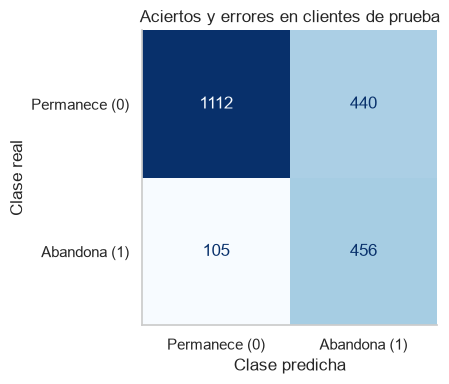

In [156]:
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(matrix, display_labels=["Permanece (0)", "Abandona (1)"]).plot(
    cmap="Blues", values_format="d", colorbar=False,
)
plt.grid(False)
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title("Aciertos y errores en clientes de prueba")
plt.tight_layout()
plt.show()

| Real → predicha | Nombre | Interpretación |
| --- | --- | --- |
| Permanece → permanece | TN: verdadero negativo | Permanencia correcta |
| Permanece → abandona | FP: falso positivo | Contacto innecesario |
| Abandona → permanece | FN: falso negativo | Abandono sin identificar |
| Abandona → abandona | TP: verdadero positivo | Abandono identificado |

### Accuracy, precisión y recall

| Métrica | Cálculo | Pregunta que responde |
| --- | --- | --- |
| Accuracy | `(TP + TN) / total` | ¿Qué proporción de clientes clasificamos bien? |
| Precisión | `TP / (TP + FP)` | ¿Cuánto acertamos entre los clientes señalados? |
| Recall | `TP / (TP + FN)` | ¿Qué proporción de abandonos detectamos? |

La selección ya se hizo por recall de validación. Ahora medimos el resultado final.


Si no señalamos ningún abandono, no podemos calcular precisión: no hay contactos
que evaluar. `zero_division=np.nan` muestra ese caso como `NaN` («sin valor»).


In [147]:
metrics = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, baseline_pred)],
    "Precisión": [precision_score(y_test, y_pred, zero_division=np.nan),
                  precision_score(y_test, baseline_pred, zero_division=np.nan)],
    "Recall": [recall_score(y_test, y_pred), recall_score(y_test, baseline_pred)],
}, index=[type(best_model.named_steps["model"]).__name__, "Baseline: clase mayoritaria"])
metrics.round(3)

,Accuracy,Precisión,Recall
RandomForestClassifier,0.742,0.509,0.813
Baseline: clase mayoritaria,0.735,NaN,0.000


El bosque detecta **456 de 561 abandonos (81,3 % de recall)**. Señala a 896
clientes y acierta en 456: **50,9 % de precisión**. Quedan **105 abandonos sin
detectar** y **440 contactos innecesarios**.

La accuracy es **74,2 %**, frente a **73,5 %** del baseline. Parecen cercanas,
pero el baseline no detecta ningún abandono. Por eso accuracy sola no basta.


### Curva ROC: detección y falsas alarmas

**Ejemplo ficticio:** hay 100 clientes que abandonan y 200 que permanecen.
Detectamos 80 abandonos y señalamos por error a 20 que permanecen:

- **Eje vertical:** 80/100 = **80 % de abandonos detectados** (recall).
- **Eje horizontal:** 20/200 = **10 % de falsas alarmas entre quienes permanecen**.

Ese resultado es el punto **(0,10; 0,80)**. Cada punto de la curva usa un umbral
distinto. Queremos acercarnos a la **esquina superior izquierda**: mucha detección
y pocas falsas alarmas.

**¿Cuándo usarla?** Para comparar detección y falsas alarmas. La diagonal gris
representa una ordenación al azar. **AUC** es el área bajo la curva: 1 indica
separación perfecta y 0,5, nivel aleatorio. No es un porcentaje de aciertos.

Un 10 % de falsas alarmas entre 10.000 clientes que permanecen son 1.000 contactos
innecesarios. Para saber cuánto acertamos entre los contactos, miramos precisión–recall.

Estas curvas usan probabilidades de prueba para evaluar; el umbral se compara en validación.


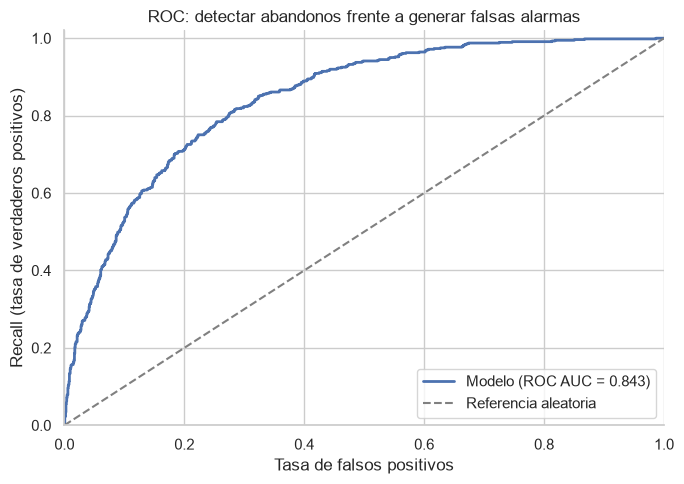

In [148]:
test_probability = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, roc_thresholds = roc_curve(y_test, test_probability)
roc_auc = roc_auc_score(y_test, test_probability)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr, tpr, label=f"Modelo (ROC AUC = {roc_auc:.3f})", linewidth=2)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referencia aleatoria")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Recall (tasa de verdaderos positivos)",
       title="ROC: detectar abandonos frente a generar falsas alarmas",
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


### Curva precisión–recall: ¿a cuántos detectamos y cuánto acertamos?

**Ejemplo ficticio:** hay 100 clientes que abandonan. Señalamos a 160 clientes
y entre ellos hay 80 que abandonan:

- **Eje horizontal, recall:** detectamos 80/100 = **80 % de los abandonos**.
- **Eje vertical, precisión:** acertamos en 80/160 = **50 % de los contactos**.

Ese resultado es el punto **(0,80; 0,50)**. Cada punto usa un umbral distinto.
Queremos acercarnos a la **esquina superior derecha**: detectar muchos abandonos
y acertar en muchos de los contactos.

**¿Cuándo usarla?** Cuando necesitamos valorar si detectar más abandonos compensa
los contactos innecesarios, especialmente si el abandono es poco frecuente.

La línea gris muestra la precisión esperada al elegir clientes al azar:
**26,5 %** en esta prueba. **AP** (*average precision*, precisión promedio) resume
la curva; cuanto mayor, mejor. No es el porcentaje total de aciertos.


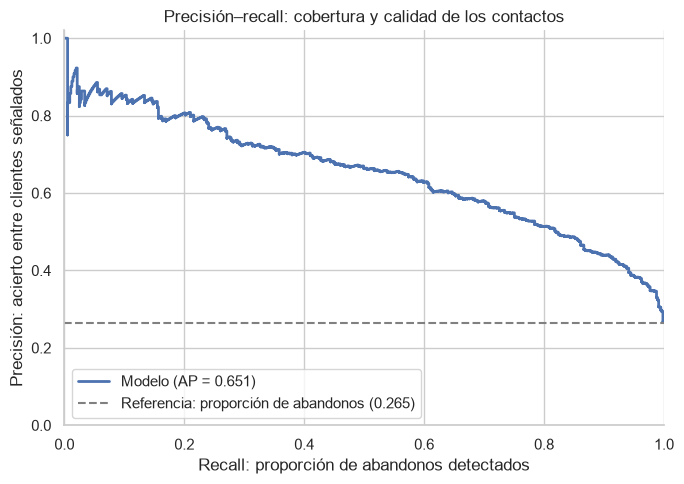

In [149]:
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_test, test_probability)
average_precision = average_precision_score(y_test, test_probability)

fig, ax = plt.subplots(figsize=(7, 5))
ax.step(pr_recall, pr_precision, where="post", linewidth=2,
        label=f"Modelo (AP = {average_precision:.3f})")
ax.axhline(y_test.mean(), linestyle="--", color="gray",
           label=f"Referencia: proporción de abandonos ({y_test.mean():.3f})")
ax.set(xlabel="Recall: proporción de abandonos detectados",
       ylabel="Precisión: acierto entre clientes señalados",
       title="Precisión–recall: cobertura y calidad de los contactos",
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()


## 6. Uso de los resultados

Tomamos un cliente de prueba para ver una predicción paso a paso.
Mostramos sus entradas; no es una nueva evaluación.


In [150]:
customer_index = X_test.index[0]
held_out_customer = X_test.loc[[customer_index]]
held_out_customer.T.rename(columns={customer_index: "Entrada real"})

,Entrada real
tenure,18
MultipleLines,No
InternetService,Fiber optic
OnlineSecurity,Yes
OnlineBackup,No
DeviceProtection,No
TechSupport,No
StreamingTV,Yes
StreamingMovies,Yes
Contract,Month-to-month


El pipeline prepara la fila y aplica el bosque. `predict_proba()` devuelve las
probabilidades de las clases 0 y 1; `[0, 1]` elige la primera fila y la clase abandono.
Comparamos esa probabilidad con la clase predicha y lo que realmente ocurrió.


In [151]:
customer_probability = best_model.predict_proba(held_out_customer)[0, 1]
customer_prediction = best_model.predict(held_out_customer)[0]
print(f"Cliente: {customer_ids.loc[customer_index]}")
print(f"Probabilidad estimada de abandono: {customer_probability:.1%}")
print(f"Clase predicha: {customer_prediction}; clase real: {y_test.loc[customer_index]}")

Cliente: 9692-TUSXH
Probabilidad estimada de abandono: 73.5%
Clase predicha: 1; clase real: 1


Para este cliente, la probabilidad estimada de abandono es **73,5 %** y la clase
predicha es **1**, que coincide con la real. Esa cifra no garantiza lo que pasará.

El bosque balanceado de profundidad 6 detecta aproximadamente **cuatro de cada
cinco abandonos**, pero cerca de la mitad de los contactos serían innecesarios.
Su utilidad depende del costo y la capacidad de la campaña. Predecir abandono
no demuestra que contactar al cliente lo evite.


## Referencias

Documentación oficial para consultar los conceptos y las herramientas de la sesión.

### Datos y exploración

- [Telco Customer Churn, versión 1](https://www.kaggle.com/datasets/blastchar/telco-customer-churn/versions/1).
- [KaggleHub: descarga y caché](https://github.com/Kaggle/kagglehub#download-datasets).
- [pandas: primeros pasos](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html), [groupby](https://pandas.pydata.org/docs/user_guide/groupby.html) y [tablas cruzadas](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html).

### Preparación

- [Opciones de imputación](https://scikit-learn.org/stable/modules/impute.html), [KNNImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html) e [IterativeImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.IterativeImputer.html).
- [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html), [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) y [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).
- [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) y [evitar fuga de información](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

### Modelos y validación

- [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [KNN](https://scikit-learn.org/stable/modules/neighbors.html#nearest-neighbors-classification), [árboles](https://scikit-learn.org/stable/modules/tree.html) y [bosques](https://scikit-learn.org/stable/modules/ensemble.html#forest).
- [DummyClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html), [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html) y [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

### Evaluación

- [Promedios de recall: binary, macro y weighted](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html) y [balanced accuracy](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html).
- [Curva ROC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html) y [ROC AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).
- [Curva precisión–recall](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html) y [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
- [Umbrales de decisión](https://scikit-learn.org/stable/modules/classification_threshold.html) y [predicciones fuera de fold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html).
- [Matriz de confusión](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html), [accuracy](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html), [precisión](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html) y [recall](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html).

### Desbalance de clases

- [Submuestreo aleatorio](https://imbalanced-learn.org/stable/under_sampling.html): reducción de la clase mayoritaria.
- [Sobremuestreo, SMOTE y SMOTENC](https://imbalanced-learn.org/stable/over_sampling.html): repetición y generación de ejemplos.
- [Pesos de clase](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html): ponderación según las frecuencias.
- [Balanced accuracy](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html): promedio del recall por clase.
- [Remuestreo y fuga de información](https://imbalanced-learn.org/stable/common_pitfalls.html): separación de entrenamiento, validación y prueba.